# Phase 3 — EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 50)

PROC_DIR = Path('../data/processed')
df = pd.read_csv(PROC_DIR / 'olist_merged_clean.csv', parse_dates=[
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date',
])
print('Loaded shape:', df.shape)
df.head()

Loaded shape: (42724, 41)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_value,payment_installments,payment_type,n_payment_methods,review_score,review_comment_message,review_creation_date,review_answer_timestamp,price_is_outlier,freight_value_is_outlier,payment_value_is_outlier
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-02-10 10:56:00,2017-02-10 11:07:00,2017-04-10 19:55:00,2017-10-10 21:25:00,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,38.71,1.0,voucher,2.0,4.0,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,0,0,0
1,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,2018-08-08 08:55:00,2018-08-08 13:50:00,NaT,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,179.12,3.0,credit_card,1.0,5.0,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,0,0,0
2,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-09-07 21:57:00,2017-09-07 22:10:00,2017-11-07 14:58:00,NaT,2017-08-01,80bb27c7c16e8f973207a5086ab329e2,86320,congonhinhas,PR,1,060cb19345d90064d1015407193c233d,8581055ce74af1daba164fdbd55a40de,2017-07-13 22:10:13,147.90,27.36,automotivo,49.0,608.0,1.0,7150.0,65.0,10.0,65.0,auto,7112,guarulhos,SP,175.26,6.0,credit_card,1.0,4.0,NaN,2017-07-27 00:00:00,2017-07-27 22:48:30,0,0,0
3,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-11-04 12:22:00,NaT,NaT,NaT,2017-05-09,36edbb3fb164b1f16485364b6fb04c73,98900,santa rosa,RS,1,a1804276d9941ac0733cfd409f5206eb,dc8798cbf453b7e0f98745e396cc5616,2017-04-19 13:25:17,49.90,16.05,NaN,NaN,NaN,NaN,600.0,35.0,35.0,15.0,NaN,5455,sao paulo,SP,65.95,1.0,credit_card,1.0,2.0,fiquei triste por n ter me atendido.,2017-05-13 00:00:00,2017-05-13 20:25:42,0,0,0
4,82566a660a982b15fb86e904c8d32918,d3e3b74c766bc6214e0c830b17ee2341,delivered,2018-07-06 10:06:00,2018-09-06 03:13:00,2018-11-06 13:29:00,NaT,2018-07-18,e97109680b052ee858d93a539597bba7,35400,ouro preto,MG,1,72a97c271b2e429974398f46b93ae530,094ced053e257ae8cae57205592d6712,2018-06-18 03:13:12,31.90,18.23,perfumaria,59.0,685.0,1.0,450.0,16.0,17.0,16.0,perfumery,14095,ribeirao preto,SP,50.13,1.0,boleto,1.0,5.0,NaN,2018-06-20 00:00:00,2018-06-20 15:31:29,0,0,0


In [2]:
# Derived fields used throughout this notebook
df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df['order_date'] = df['order_purchase_timestamp'].dt.date
df['order_weekday'] = df['order_purchase_timestamp'].dt.day_name()
df['order_hour'] = df['order_purchase_timestamp'].dt.hour
df['delivery_time_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days
df['delivery_delay_days'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.days
print('Derived fields added.')

Derived fields added.


### 1. Sales trends

In [3]:
daily_orders = df.groupby('order_date')['order_id'].nunique().reset_index(name='n_orders')
daily_orders['order_date'] = pd.to_datetime(daily_orders['order_date'])
daily_orders = daily_orders.sort_values('order_date')
daily_orders['rolling_7d'] = daily_orders['n_orders'].rolling(7).mean()

fig = px.line(daily_orders, x='order_date', y=['n_orders', 'rolling_7d'],
              title='Daily order volume with 7-day rolling average',
              labels={'value': 'orders', 'order_date': 'date', 'variable': ''})
fig.show()

### 2. Monthly revenue

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3268934748.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(monthly_revenue['order_month'], rotation=90)


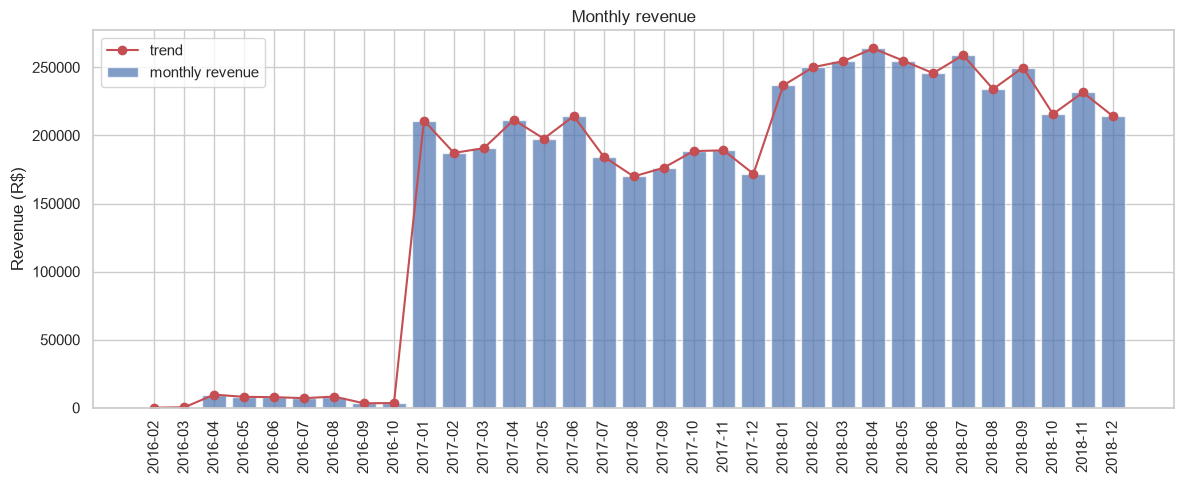

In [4]:
monthly_revenue = df.groupby('order_month')['price'].sum().reset_index(name='revenue')
monthly_revenue = monthly_revenue.sort_values('order_month')

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_revenue['order_month'], monthly_revenue['revenue'], color='#4C72B0', alpha=0.7, label='monthly revenue')
ax.plot(monthly_revenue['order_month'], monthly_revenue['revenue'], color='#C44E52', marker='o', label='trend')
ax.set_xticklabels(monthly_revenue['order_month'], rotation=90)
ax.set_ylabel('Revenue (R$)')
ax.set_title('Monthly revenue')
ax.legend()
plt.tight_layout()
plt.show()

### 3. Category popularity

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\2378450226.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_categories.index, x=top_categories['revenue'], ax=ax, palette='viridis')


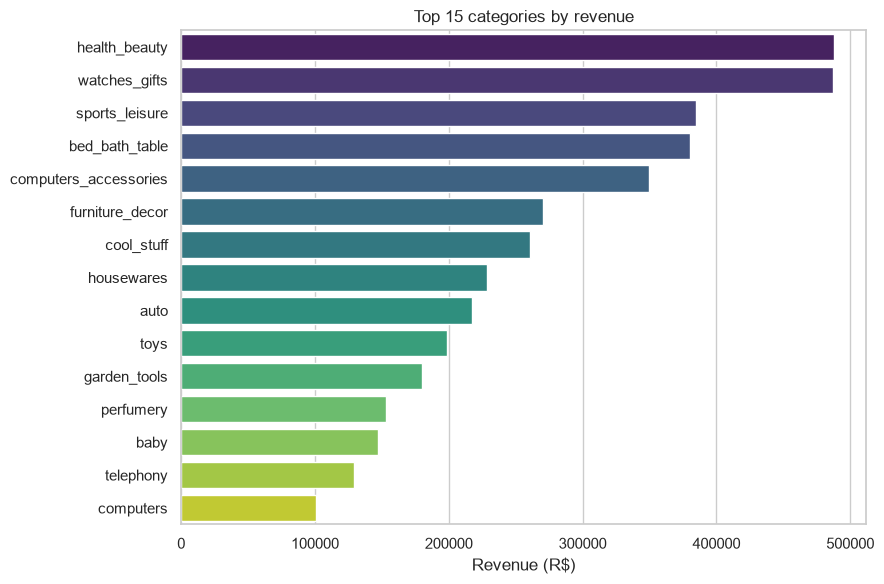

In [5]:
top_categories = (df.groupby('product_category_name_english')
                    .agg(n_orders=('order_id', 'nunique'), revenue=('price', 'sum'))
                    .sort_values('revenue', ascending=False)
                    .head(15))

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(y=top_categories.index, x=top_categories['revenue'], ax=ax, palette='viridis')
ax.set_xlabel('Revenue (R$)')
ax.set_ylabel('')
ax.set_title('Top 15 categories by revenue')
plt.tight_layout()
plt.show()

### 4. Top selling products

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3723798745.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=labels, x=top_products['units_sold'], ax=ax, palette='mako')


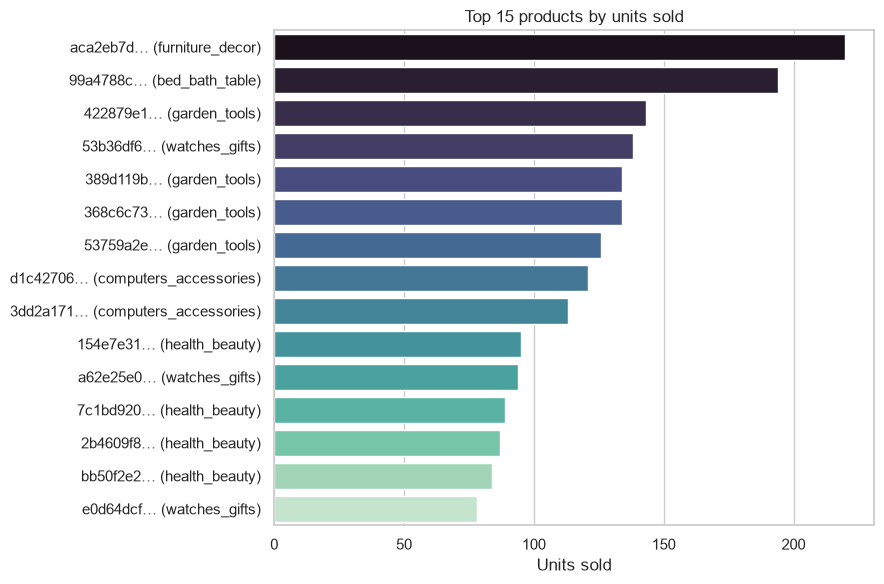

In [6]:
top_products = (df.groupby('product_id')
                  .agg(units_sold=('order_item_id', 'count'), revenue=('price', 'sum'),
                       category=('product_category_name_english', 'first'))
                  .sort_values('units_sold', ascending=False)
                  .head(15))

fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{pid[:8]}… ({cat})" for pid, cat in zip(top_products.index, top_products['category'])]
sns.barplot(y=labels, x=top_products['units_sold'], ax=ax, palette='mako')
ax.set_xlabel('Units sold')
ax.set_ylabel('')
ax.set_title('Top 15 products by units sold')
plt.tight_layout()
plt.show()

### 5. Customer distribution

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\100441508.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=customers_by_state.values, y=customers_by_state.index, ax=axes[1], palette='crest')


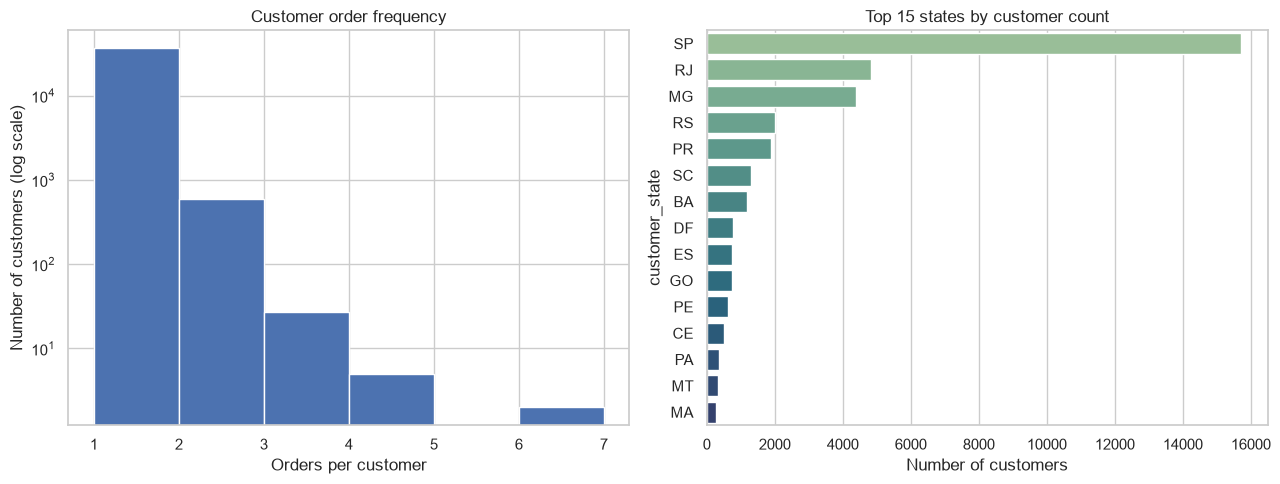

1.69% of customers placed more than one order (repeat customers)


In [7]:
orders_per_customer = df.groupby('customer_unique_id')['order_id'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(orders_per_customer, bins=range(1, orders_per_customer.max() + 2), color='#4C72B0', edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_xlabel('Orders per customer')
axes[0].set_ylabel('Number of customers (log scale)')
axes[0].set_title('Customer order frequency')

customers_by_state = df.drop_duplicates('customer_unique_id')['customer_state'].value_counts().head(15)
sns.barplot(x=customers_by_state.values, y=customers_by_state.index, ax=axes[1], palette='crest')
axes[1].set_xlabel('Number of customers')
axes[1].set_title('Top 15 states by customer count')
plt.tight_layout()
plt.show()

pct_repeat = (orders_per_customer > 1).mean() * 100
print(f'{pct_repeat:.2f}% of customers placed more than one order (repeat customers)')

### 6. Seller distribution

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\1266884460.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_data, x='seller_state', y='revenue', ax=ax, palette='Set2', showfliers=False)


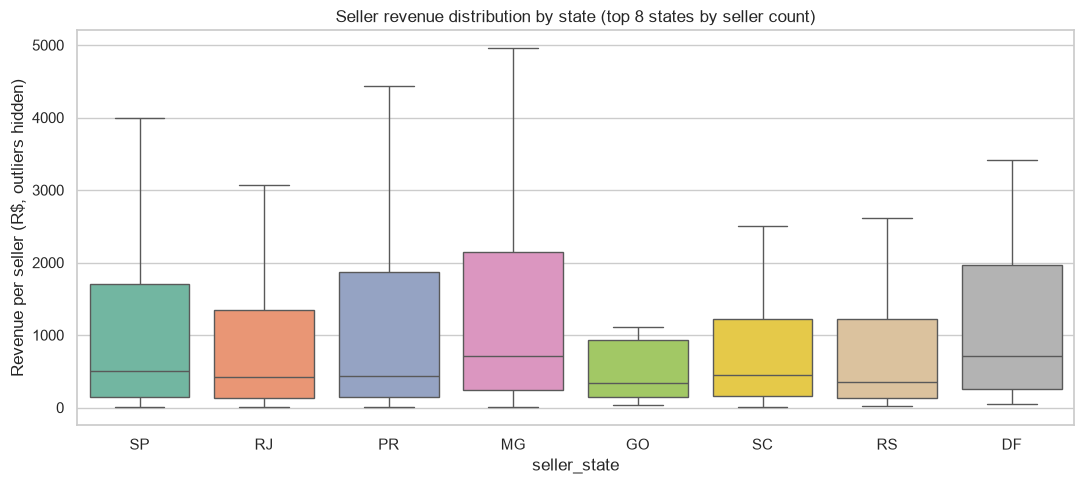

In [8]:
seller_revenue = df.groupby('seller_id')['price'].sum().reset_index(name='revenue')
sellers_by_state = df.drop_duplicates('seller_id')[['seller_id', 'seller_state']]
seller_revenue = seller_revenue.merge(sellers_by_state, on='seller_id')

top_states = seller_revenue['seller_state'].value_counts().head(8).index
plot_data = seller_revenue[seller_revenue['seller_state'].isin(top_states)]

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=plot_data, x='seller_state', y='revenue', ax=ax, palette='Set2', showfliers=False)
ax.set_ylabel('Revenue per seller (R$, outliers hidden)')
ax.set_title('Seller revenue distribution by state (top 8 states by seller count)')
plt.tight_layout()
plt.show()

### 7. Delivery performance

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3595569566.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=delivery[delivery['customer_state'].isin(top_states)],


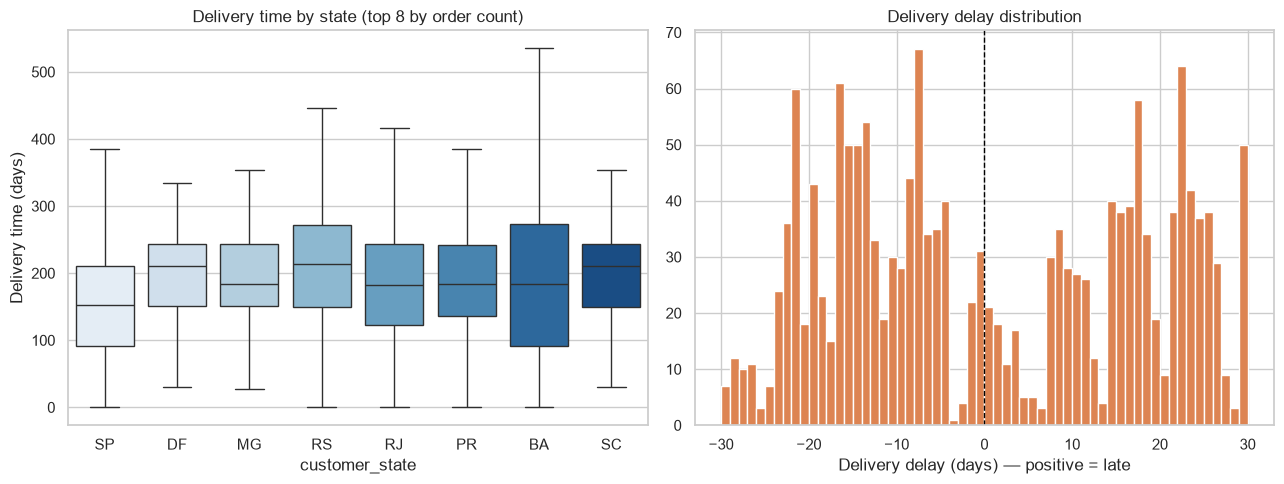

74.96% of delivered orders arrived later than the estimated date


In [9]:
delivery = df.dropna(subset=['delivery_time_days', 'delivery_delay_days'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot: delivery time by top states
top_states = delivery['customer_state'].value_counts().head(8).index
sns.boxplot(data=delivery[delivery['customer_state'].isin(top_states)],
            x='customer_state', y='delivery_time_days', ax=axes[0], palette='Blues', showfliers=False)
axes[0].set_ylabel('Delivery time (days)')
axes[0].set_title('Delivery time by state (top 8 by order count)')

# Histogram: delivery delay
axes[1].hist(delivery['delivery_delay_days'], bins=60, range=(-30, 30), color='#DD8452', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Delivery delay (days) — positive = late')
axes[1].set_title('Delivery delay distribution')
plt.tight_layout()
plt.show()

pct_late = (delivery['delivery_delay_days'] > 0).mean() * 100
print(f'{pct_late:.2f}% of delivered orders arrived later than the estimated date')

### 8. Payment method analysis

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3944080085.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_counts.values, y=payment_counts.index, ax=axes[0], palette='rocket')
C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3944080085.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=payment_orders, x='payment_type', y='payment_value', ax=axes[1],


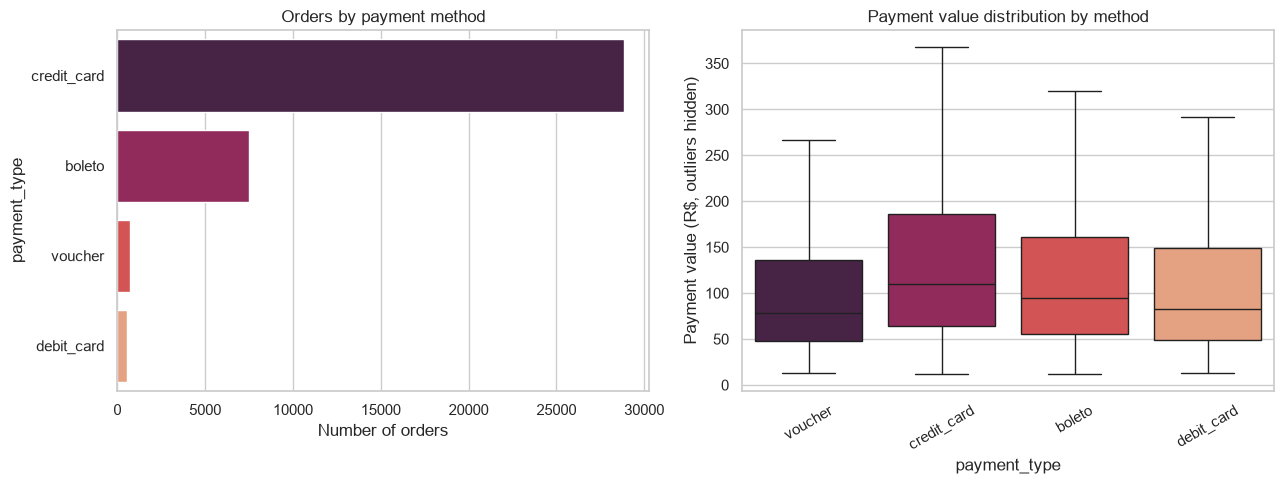

In [10]:
payment_orders = df.drop_duplicates('order_id')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

payment_counts = payment_orders['payment_type'].value_counts()
sns.barplot(x=payment_counts.values, y=payment_counts.index, ax=axes[0], palette='rocket')
axes[0].set_xlabel('Number of orders')
axes[0].set_title('Orders by payment method')

sns.boxplot(data=payment_orders, x='payment_type', y='payment_value', ax=axes[1],
            palette='rocket', showfliers=False)
axes[1].set_ylabel('Payment value (R$, outliers hidden)')
axes[1].set_title('Payment value distribution by method')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### 9. Review score distribution

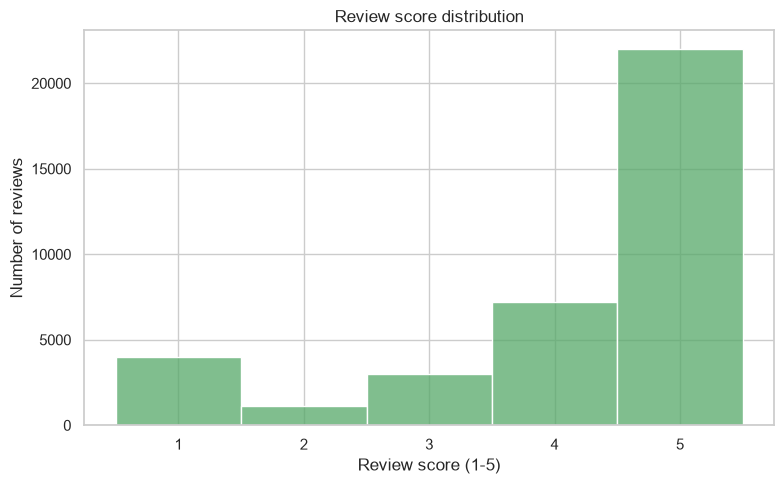

Average review score: 4.13 / 5   |   5-star share: 58.9%


In [11]:
reviewed = df.drop_duplicates('order_id').dropna(subset=['review_score'])

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(reviewed['review_score'], bins=5, discrete=True, ax=ax, color='#55A868')
ax.set_xlabel('Review score (1-5)')
ax.set_ylabel('Number of reviews')
ax.set_title('Review score distribution')
ax.set_xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

avg_score = reviewed['review_score'].mean()
pct_5star = (reviewed['review_score'] == 5).mean() * 100
print(f'Average review score: {avg_score:.2f} / 5   |   5-star share: {pct_5star:.1f}%')

C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\3513261723.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=review_delay, x='delay_bucket', y='review_score', ax=ax, palette='coolwarm')


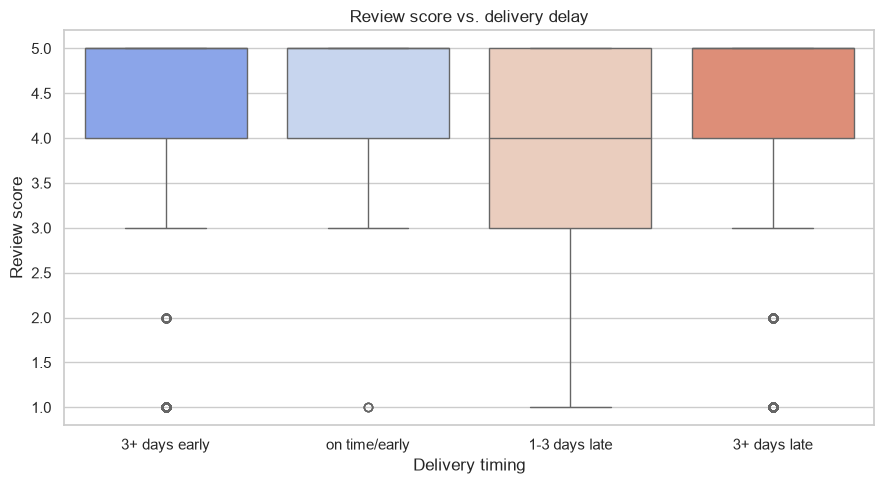

In [12]:
# Relationship between delivery delay and review score — a natural follow-up
review_delay = df.drop_duplicates('order_id').dropna(subset=['review_score', 'delivery_delay_days'])
review_delay['delay_bucket'] = pd.cut(
    review_delay['delivery_delay_days'],
    bins=[-100, -3, 0, 3, 100],
    labels=['3+ days early', 'on time/early', '1-3 days late', '3+ days late']
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=review_delay, x='delay_bucket', y='review_score', ax=ax, palette='coolwarm')
ax.set_xlabel('Delivery timing')
ax.set_ylabel('Review score')
ax.set_title('Review score vs. delivery delay')
plt.tight_layout()
plt.show()

### 10. Geographic sales patterns

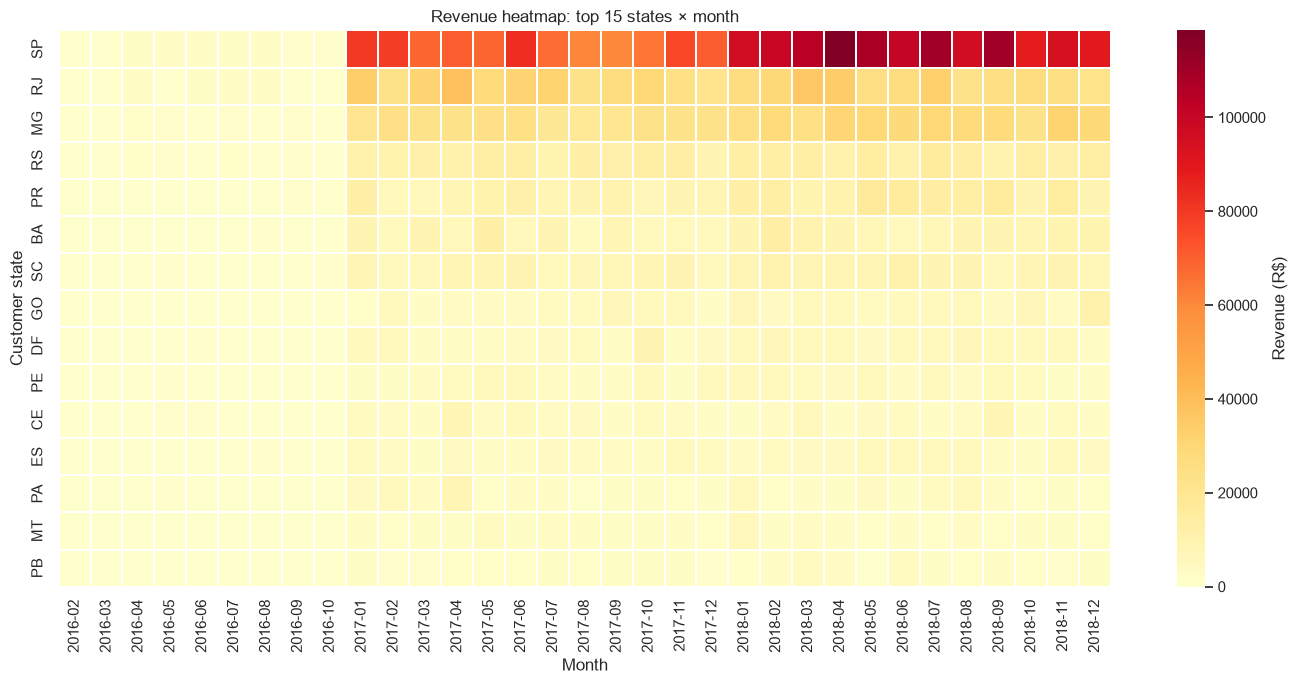

In [13]:
state_month_revenue = df.pivot_table(
    index='customer_state', columns='order_month', values='price', aggfunc='sum', fill_value=0
)
# keep only the top 15 states by total revenue, otherwise the heatmap is unreadable
top15_states = state_month_revenue.sum(axis=1).sort_values(ascending=False).head(15).index
state_month_revenue = state_month_revenue.loc[top15_states]

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(state_month_revenue, cmap='YlOrRd', ax=ax, linewidths=0.3, cbar_kws={'label': 'Revenue (R$)'})
ax.set_title('Revenue heatmap: top 15 states × month')
ax.set_xlabel('Month')
ax.set_ylabel('Customer state')
plt.tight_layout()
plt.show()

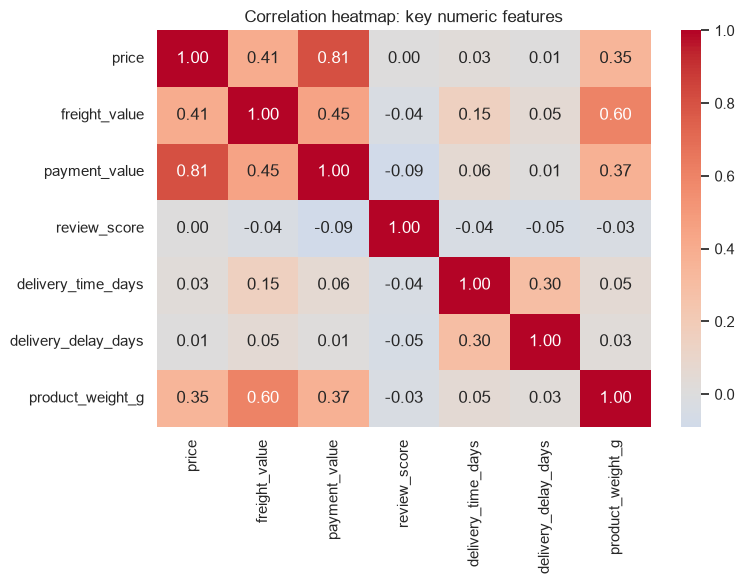

In [14]:
# Correlation heatmap across key numeric fields — a second, distinct use of "heatmap"
numeric_cols = ['price', 'freight_value', 'payment_value', 'review_score',
                'delivery_time_days', 'delivery_delay_days', 'product_weight_g']
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation heatmap: key numeric features')
plt.tight_layout()
plt.show()

Choropleth failed (Extra data: line 1 column 4 (char 3)); showing fallback bar chart instead.


C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29540\212309759.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sorted_rev, x='revenue', y='customer_state', ax=ax, palette='YlOrRd_r')


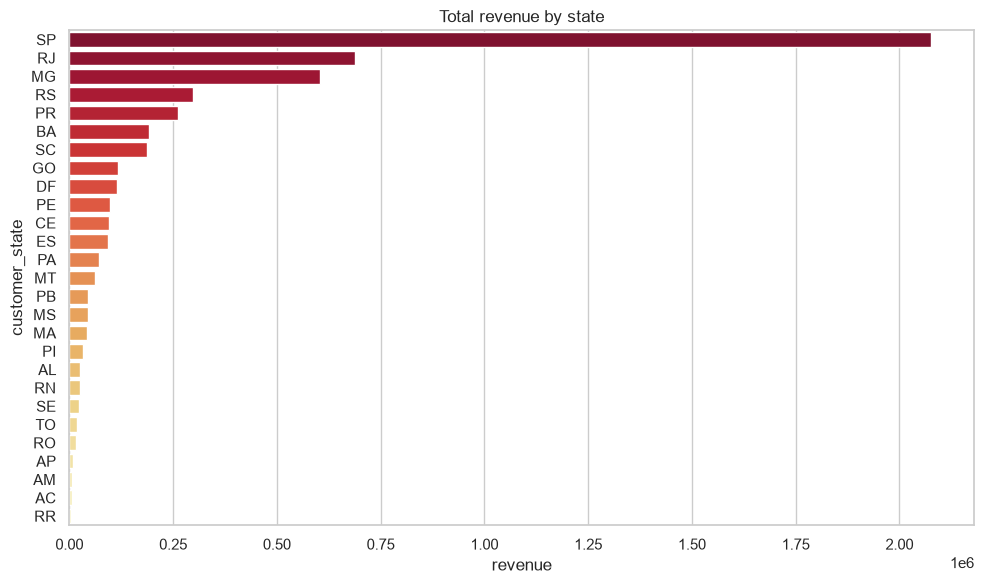

In [15]:
state_revenue = df.groupby('customer_state')['price'].sum().reset_index(name='revenue')

try:
    import requests
    geojson_url = 'https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-100-uf.json'
    brazil_geojson = requests.get(geojson_url, timeout=10).json()

    fig = px.choropleth(
        state_revenue, geojson=brazil_geojson, locations='customer_state',
        featureidkey='properties.id', color='revenue',
        color_continuous_scale='YlOrRd',
        title='Total revenue by state (choropleth)',
    )
    fig.update_geos(fitbounds='locations', visible=False)
    fig.show()
except Exception as e:
    print(f'Choropleth failed ({e}); showing fallback bar chart instead.')
    fig, ax = plt.subplots(figsize=(10, 6))
    sorted_rev = state_revenue.sort_values('revenue', ascending=False)
    sns.barplot(data=sorted_rev, x='revenue', y='customer_state', ax=ax, palette='YlOrRd_r')
    ax.set_title('Total revenue by state')
    plt.tight_layout()
    plt.show()